# Frequency comb explorer: Zheng et al., Phys. Rev. Applied 25, 024022 (2026)

Interactive model of the two coupled membrane modes, (0,1) → `x` and (2,1) → `y`:

$$\ddot x + c_1\dot x + \omega_1^2 x + \alpha_1 x^2 + \beta_1 x^3 + \text{(coupling)}_x = \Gamma\cos\phi_D(t)$$
$$\ddot y + c_2\dot y + \omega_2^2 y + \alpha_2 y^2 + \beta_2 y^3 + \text{(coupling)}_y = 0$$

**How to use it**
1. Run all cells (Kernel → Restart & Run All). The last cell shows the controls.
2. Choose a **temperature**. ω₁, Q₁, β₁ and X₀ come from Table S2, and ω₂ from Table S3. These are fixed and shown in the grey box.
3. Set the **unknowns** with the sliders: Γ, λ₁, λ₂, β₂, α. Or start from a **preset**.
4. Press **Run**. Each run takes about 0.2 s. You get the amplitude over time and the spectrum around f_D and 2f_D, with comb lines and spacing Δf detected automatically.

**Drive protocol:** the drive frequency ramps from `f_start` up to `f_D`, then holds. After a settle time, the spectrum is taken over the FFT window (shaded grey in the plot). Ramping up the way the experiment does matters, because the same parameters can give a comb after a ramp and chaos or a steady tone without one.

**Paper target (270 K, +5 dBm):** f_D = 4.1504 MHz → Δf = 33.315 kHz, 11 lines around 2f_D.

ε = 1 throughout (it is only a perturbation bookkeeping factor). Units are SI: x, y in meters and Γ in m/s².

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import ipywidgets as W
from IPython.display import display, HTML
try:
    from numba import njit
    FAST = True
except ImportError:                      # pip install numba  (about 400x faster)
    FAST = False
    def njit(*a, **k):
        return (lambda f: f) if not a or not callable(a[0]) else a[0]
    print("numba not found: runs will take minutes. Install it with  pip install numba")
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


## 1. Fixed parameters: Tables S2 and S3 of the supplement

In [2]:
# T [K]: f0,(0,1) [Hz], Q1, beta1 [m^-2 s^-2], X0 [m], f0,(2,1) [Hz]
TABLE = {
    250: dict(f1=3.551e6,   Q1=1389, beta1=4.81e27,   X0=156.92e-9, f2=7.995e6),
    260: dict(f1=3.52625e6, Q1=1371, beta1=2.482e27,  X0=118.43e-9, f2=7.933e6),
    270: dict(f1=3.5105e6,  Q1=1326, beta1=1.8453e27, X0=79.94e-9,  f2=7.870e6),
    280: dict(f1=3.4735e6,  Q1=1199, beta1=1.537e27,  X0=41.45e-9,  f2=7.805e6),
    290: dict(f1=3.42675e6, Q1=1120, beta1=1.36e27,   X0=2.96e-9,   f2=7.737e6),
    300: dict(f1=3.3969e6,  Q1=987,  beta1=1.2453e27, X0=-33.53e-9, f2=7.668e6),
}
Q2_DEFAULT = 1223          # mode (2,1), measured at 300 K only (main text, Fig. 1d)
M_EFF, D_IJ = 2.916e-12, 1.338e-9   # kg, m/V (Table S2; not used by the model)

## 2. Simulator
Fixed-step 4th-order Runge–Kutta, compiled with numba, at 64 steps per period of the fastest oscillation. It was checked against SciPy's `DOP853` at `rtol=1e-10`: identical comb lines and waveforms within 1%. It also reproduces the original Mathematica comb from `Comb_Code.nb` line for line.

Coupling forms (`form`):
- **0 (Mathematica code, recommended):** `λ₁·x·y` in the x equation, `λ₂·x²` in the y equation. This is a 1:2 three-wave coupling that can pump mode (2,1) from rest.
- **1 (Supplement S1.2):** `λ₁·x·y²` in the x equation, `λ₂·x²·y` in the y equation.
- **2 (Main text Eqs. 1.1/1.2):** `λ₁·x·y` in the x equation, `λ₂·x·y` in the y equation.

Forms 1 and 2 have y in every term of the y equation, so y stays at 0 unless you give it a nonzero **y seed**. Their λ also has different units (m⁻²s⁻² for the cubic `x·y²` and `x²·y` terms), so the presets' λ values don't carry over. Expect to need λ around the size of β (≈10²⁷).

In [3]:
@njit
def _acc(x, v, y, w, phase, P):
    w1sq, c1, a1, b1, w2sq, c2, a2, b2, l1, l2, G, form = P[0],P[1],P[2],P[3],P[4],P[5],P[6],P[7],P[8],P[9],P[10],P[11]
    if form == 0:
        cx = l1*x*y;   cy = l2*x*x
    elif form == 1:
        cx = l1*x*y*y; cy = l2*x*x*y
    else:
        cx = l1*x*y;   cy = l2*x*y
    ax = G*np.cos(phase) - c1*v - w1sq*x - a1*x*x - b1*x*x*x - cx
    ay = -c2*w - w2sq*y - a2*y*y - b2*y*y*y - cy
    return ax, ay

@njit
def _simulate(P, s0, f_start, f_end, t_ramp, t_total, dt, dec, xmax):
    n = int(t_total/dt); nout = n//dec + 1
    T = np.empty(nout); X = np.empty(nout); Y = np.empty(nout); FD = np.empty(nout)
    x, v, y, w = s0[0], s0[1], s0[2], s0[3]
    twopi = 2*np.pi
    rate = (f_end - f_start)/t_ramp if t_ramp > 0 else 0.0
    ph_end = twopi*(f_start*t_ramp + 0.5*rate*t_ramp*t_ramp)
    ph = np.empty(3); k = 0
    for i in range(n+1):
        t = i*dt
        if i % dec == 0 and k < nout:
            T[k] = t; X[k] = x; Y[k] = y
            FD[k] = f_start + rate*t if t < t_ramp else f_end
            k += 1
        if i == n:
            break
        for j in range(3):
            tj = t + 0.5*dt*j
            ph[j] = twopi*(f_start*tj + 0.5*rate*tj*tj) if tj < t_ramp else ph_end + twopi*f_end*(tj - t_ramp)
        ax1, ay1 = _acc(x, v, y, w, ph[0], P)
        x2 = x + 0.5*dt*v;  v2 = v + 0.5*dt*ax1; y2 = y + 0.5*dt*w;  w2 = w + 0.5*dt*ay1
        ax2, ay2 = _acc(x2, v2, y2, w2, ph[1], P)
        x3 = x + 0.5*dt*v2; v3 = v + 0.5*dt*ax2; y3 = y + 0.5*dt*w2; w3 = w + 0.5*dt*ay2
        ax3, ay3 = _acc(x3, v3, y3, w3, ph[1], P)
        x4 = x + dt*v3;     v4 = v + dt*ax3;     y4 = y + dt*w3;     w4 = w + dt*ay3
        ax4, ay4 = _acc(x4, v4, y4, w4, ph[2], P)
        x += dt/6*(v + 2*v2 + 2*v3 + v4);  v += dt/6*(ax1 + 2*ax2 + 2*ax3 + ax4)
        y += dt/6*(w + 2*w2 + 2*w3 + w4);  w += dt/6*(ay1 + 2*ay2 + 2*ay3 + ay4)
        if not (abs(x) < xmax and abs(y) < xmax):       # blow-up guard
            break
    return T[:k], X[:k], Y[:k], FD[:k]

## 3. Spectrum and comb detection

In [4]:
def spectrum(T, sig, t0):
    # Hann-windowed amplitude spectrum of sig over t >= t0
    m = T >= t0
    s = sig[m] - sig[m].mean()
    win = np.hanning(len(s))
    S = np.abs(np.fft.rfft(s*win)) / (win.sum()/2)
    f = np.fft.rfftfreq(len(s), T[1]-T[0])
    return f, S

def comb_lines(f, S_db, fc, span, floor_db=-60, prom_db=10):
    # Peaks within +-span of fc that are above floor_db (relative to the overall max) and stand out by prom_db
    m = (f > fc-span) & (f < fc+span)
    pk, _ = find_peaks(S_db[m], height=floor_db, prominence=prom_db)
    fp = np.sort(f[m][pk])
    df = np.median(np.diff(fp)) if len(fp) > 1 else np.nan
    return fp, df

## 4. One model run (usable without the sliders, e.g. for scripted parameter sweeps)

In [5]:
def run_model(T_K=270, Gamma=10**7.4, lam1=10**21.5, lam2=10**19.5, beta2_ratio=1.0, alpha1=0.0, alpha2=0.0,
              Q2=Q2_DEFAULT, form=0, damping="w0/Q", fD=4.1504e6, f_start=3.4e6,
              t_ramp=2e-3, t_settle=1.0e-3, t_fft=1.5e-3, y_seed=0.0, x0_from_table=False):
    p = TABLE[T_K]
    w1, w2 = 2*np.pi*p["f1"], 2*np.pi*p["f2"]
    k = 1.0 if damping == "w0/Q" else 0.5           # "w0/2Q" = paper's eta (half the damping)
    c1, c2 = k*w1/p["Q1"], k*w2/Q2
    beta2 = beta2_ratio*p["beta1"]
    P = np.array([w1**2, c1, alpha1, p["beta1"], w2**2, c2, alpha2, beta2, lam1, lam2, Gamma, form], float)
    s0 = np.array([p["X0"] if x0_from_table else 0.0, 0.0, y_seed, 0.0])
    fmax = 1.3*max(p["f2"], 2*fD, p["f1"], fD)
    dt = 1/(64*fmax)
    dec = max(1, int(round(1/(50e6*dt))))          # store at ~50 MS/s
    t_ramp = t_ramp if f_start != fD else 0.0
    t_total = t_ramp + t_settle + t_fft
    T, X, Y, FD = _simulate(P, s0, f_start, fD, t_ramp, t_total, dt, dec, 1e-3)
    blew_up = T[-1] < 0.99*t_total
    out = dict(T=T, X=X, Y=Y, FD=FD, blew_up=blew_up, t_hold_start=t_ramp + t_settle, fD=fD, params=p, c1=c1, c2=c2, beta2=beta2)
    if not blew_up:
        f, S = spectrum(T, X + Y, t_ramp + t_settle)
        S_db = 20*np.log10(np.maximum(S/S.max(), 1e-12))
        span = min(1.5e6, 0.45*fD)
        out.update(f=f, S_db=S_db, span=span,
                   comb1=comb_lines(f, S_db, fD, span), comb2=comb_lines(f, S_db, 2*fD, span))
    return out

## 5. Plotting

In [6]:
def envelope(T, s, nbins=2000):
    n = len(s)//nbins*nbins
    if n == 0: return T, np.abs(s)
    return T[:n].reshape(nbins, -1).mean(1), np.abs(s[:n]).reshape(nbins, -1).max(1)

def plot_run(r, title=""):
    fig = plt.figure(figsize=(13, 7.5))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1])
    ax0 = fig.add_subplot(gs[0, :])
    for s, lab in [(r["X"], "x  mode (0,1)"), (r["Y"], "y  mode (2,1)")]:
        te, se = envelope(r["T"], s)
        ax0.plot(te*1e3, se*1e9, lw=1, label=lab)
    ax0.axvspan(r["t_hold_start"]*1e3, r["T"][-1]*1e3, color="0.92", zorder=-1, label="FFT window")
    ax0.set_xlabel("Time (ms)"); ax0.set_ylabel("Amplitude envelope (nm)")
    axf = ax0.twinx(); te, fe = envelope(r["T"], r["FD"]); axf.plot(te*1e3, fe/1e6, "k--", lw=0.8)
    axf.set_ylabel("Drive frequency (MHz)", color="0.3")
    ax0.legend(loc="upper left", fontsize=9); ax0.set_title(title, fontsize=10, loc="left")
    if r["blew_up"]:
        ax0.text(0.5, 0.5, "Solution blew up (>1 mm), so try smaller Γ or couplings", transform=ax0.transAxes,
                 ha="center", color="red", fontsize=13)
        plt.show(); return
    for j, (fc, key, lab) in enumerate([(r["fD"], "comb1", "around f_D (m = 1)"), (r["fD"]*2, "comb2", "around 2f_D (m = 2)")]):
        ax = fig.add_subplot(gs[1, j])
        m = (r["f"] > fc - r["span"]) & (r["f"] < fc + r["span"])
        ax.plot((r["f"][m] - fc)/1e3, r["S_db"][m], lw=0.8)
        fp, df = r[key]
        ax.plot((fp - fc)/1e3, np.interp(fp, r["f"], r["S_db"]), "rv", ms=4)
        txt = f"{len(fp)} lines" + (f", Δf ≈ {df/1e3:.1f} kHz" if len(fp) > 1 else "")
        ax.set_title(f"{lab}: {txt}", fontsize=10)
        ax.set_xlabel(f"Frequency − {fc/1e6:.4f} MHz (kHz)"); ax.set_ylabel("Amplitude (dB)")
        ax.set_ylim(-100, 5)
    plt.tight_layout(); plt.show()

def summary(r):
    p = r["params"]
    if r["blew_up"]:
        return "<b style='color:red'>Blew up</b>"
    n1, df1 = len(r["comb1"][0]), r["comb1"][1]
    n2, df2 = len(r["comb2"][0]), r["comb2"][1]
    m = r["T"] >= r["t_hold_start"]
    verdict = ("steady tone, no comb" if max(n1, n2) <= 1 else
               "probably chaotic or broadband (many irregular lines)" if max(n1, n2) > 40 else "comb")
    fmt = lambda n, d: f"{n} lines" + (f", Δf ≈ <b>{d/1e3:.2f} kHz</b>" if n > 1 else "")
    return (f"<b>Result:</b> {verdict}. Around f_D: {fmt(n1, df1)}. Around 2f_D: {fmt(n2, df2)}."
            + f"<br>Hold-window peak amplitudes: x = {np.abs(r['X'][m]).max()*1e9:.0f} nm, y = {np.abs(r['Y'][m]).max()*1e9:.0f} nm"
            + "<br><span style='color:#666'>Paper target (270 K, f_D = 4.1504 MHz): Δf = 33.315 kHz, 11 lines at m = 2</span>")

## 6. Example run (static, default preset)

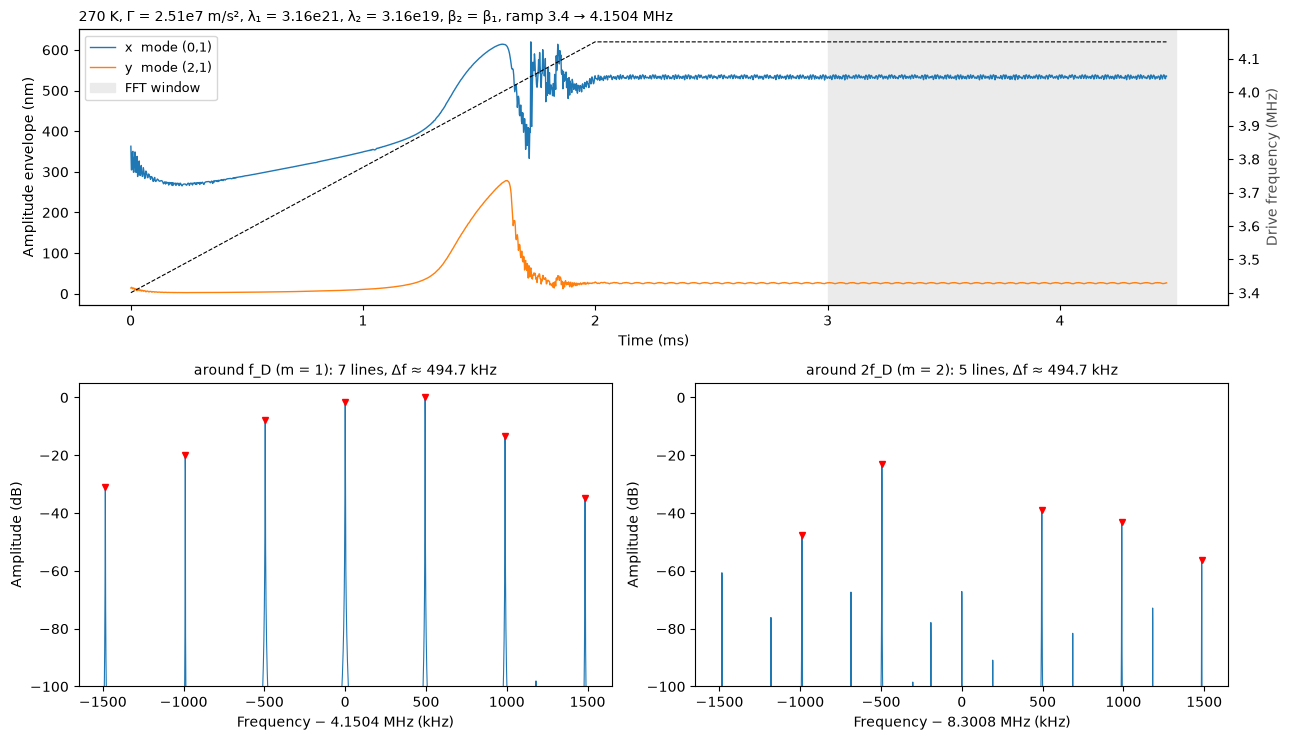

In [7]:
r = run_model()       # 270 K, "Clean comb" preset values
display(HTML(summary(r)))
plot_run(r, "270 K, Γ = 2.51e7 m/s², λ₁ = 3.16e21, λ₂ = 3.16e19, β₂ = β₁, ramp 3.4 → 4.1504 MHz")

## 7. Interactive explorer
Presets were found with a coarse grid search at 270 K and f_D = 4.1504 MHz, and checked to give the same state with a longer settle time and with Γ nudged by 1e-9 to 1e-3.

**Expect sensitivity near the chaos boundary.** There the system has several stable comb states, and which one a run lands on can change with a Γ change as small as 1 part in 10¹² (try the "Near chaos" preset and move Γ by one step). The measured data show the same behavior: Δf jumps between distinct lines (supplement Fig. S7). For calibration, run several slightly perturbed copies of each setting and look at the spread, not a single run. None of them reproduces the paper's 33 kHz spacing yet. Finding settings that do is the calibration task.

In [1]:
S = {"description_width": "150px"}; L = W.Layout(width="440px")
PRESETS = {   # values sit exactly on the slider grid; each was checked to give the same state when Γ is nudged by 1e-9 to 1e-3
    "Clean comb, 7 lines (~495 kHz)":   dict(Gamma=10**7.4, lam1=10**21.5, lam2=10**19.5),
    "Comb, 15 lines (~227 kHz)":        dict(Gamma=10**7.4, lam1=10**22.5, lam2=10**19.5),
    "Near chaos (sensitive)":           dict(Gamma=10**7.4, lam1=10**22.0, lam2=10**20.0),
    "Chaos":                            dict(Gamma=10**7.9, lam1=10**22.5, lam2=10**19.5),
    "No comb (weak drive)":             dict(Gamma=10**5.5, lam1=10**19.0, lam2=10**18.0),
}
w_preset = W.Dropdown(options=["Custom"] + list(PRESETS), value="Clean comb, 7 lines (~495 kHz)", description="Preset", style=S, layout=L)
w_T      = W.Dropdown(options=sorted(TABLE), value=270, description="Temperature (K)", style=S, layout=L)
w_form   = W.Dropdown(options=[("Mathematica: λ₁xy | λ₂x²", 0), ("Supplement S1: λ₁xy² | λ₂x²y", 1), ("Main text: λ₁xy | λ₂xy", 2)],
                      value=0, description="Coupling form", style=S, layout=L)
w_damp   = W.Dropdown(options=[("c = ω₀/Q (matches measured Q)", "w0/Q"), ("c = ω₀/2Q (paper's η)", "w0/2Q")],
                      value="w0/Q", description="Damping", style=S, layout=L)
w_G   = W.FloatLogSlider(value=10**7.4, base=10, min=4, max=9, step=0.02, description="Γ (m/s²)", readout_format=".2e", style=S, layout=L)
w_l1  = W.FloatLogSlider(value=10**21.5, base=10, min=15, max=25, step=0.05, description="λ₁ (x-eq coupling)", readout_format=".2e", style=S, layout=L)
w_l2  = W.FloatLogSlider(value=10**19.5, base=10, min=12, max=23, step=0.05, description="λ₂ (y-eq coupling)", readout_format=".2e", style=S, layout=L)
w_b2  = W.FloatSlider(value=1.0, min=0, max=3, step=0.05, description="β₂ / β₁", style=S, layout=L)
w_Q2  = W.IntSlider(value=Q2_DEFAULT, min=300, max=3000, step=10, description="Q₂ (mode 2,1)", style=S, layout=L)
w_a1  = W.FloatText(value=0.0, description="α₁ (m⁻¹s⁻²)", style=S, layout=L)
w_a2  = W.FloatText(value=0.0, description="α₂ (m⁻¹s⁻²)", style=S, layout=L)
w_fD  = W.FloatSlider(value=4.1504, min=3.3, max=4.6, step=0.0001, description="f_D final (MHz)", readout_format=".4f", style=S, layout=L)
w_fs  = W.FloatSlider(value=3.4, min=3.0, max=4.6, step=0.01, description="f_start (MHz)", readout_format=".2f", style=S, layout=L)
w_tr  = W.FloatSlider(value=2.0, min=0.0, max=6.0, step=0.1, description="Ramp time (ms)", style=S, layout=L)
w_ts  = W.FloatSlider(value=1.0, min=0.0, max=4.0, step=0.1, description="Settle time (ms)", style=S, layout=L)
w_th  = W.FloatSlider(value=1.5, min=0.3, max=4.0, step=0.1, description="FFT window (ms)", style=S, layout=L)
w_ys  = W.FloatText(value=0.0, description="y seed y(0) (nm)", style=S, layout=L)
w_x0  = W.Checkbox(value=False, description="x(0) = X₀ from table", style=S)
w_run = W.Button(description="Run", button_style="success", icon="play", layout=W.Layout(width="200px", height="38px"))
fixed_box = W.HTML(); res_box = W.HTML(); plot_out = W.Output()

def show_fixed(*_):
    p = TABLE[w_T.value]; k = 1.0 if w_damp.value == "w0/Q" else 0.5
    fixed_box.value = (
        "<div style='background:#f3f3f3;padding:6px 10px;border-radius:6px;font-size:13px'>"
        f"<b>Fixed at {w_T.value} K</b> (Tables S2/S3): f₁ = {p['f1']/1e6:.5f} MHz, Q₁ = {p['Q1']}, "
        f"c₁ = 2π·{k*p['f1']/p['Q1']:.0f} Hz, β₁ = {p['beta1']:.4g} m⁻²s⁻², X₀ = {p['X0']*1e9:.2f} nm, "
        f"f₂ = {p['f2']/1e6:.3f} MHz &nbsp;|&nbsp; f₂/f₁ = {p['f2']/p['f1']:.3f}, ε = 1</div>")

def apply_preset(change):
    if change["new"] in PRESETS:
        v = PRESETS[change["new"]]
        w_G.value, w_l1.value, w_l2.value = v["Gamma"], v["lam1"], v["lam2"]
        w_preset.value = change["new"]

def mark_custom(change):
    if w_preset.value != "Custom" and w_preset.value in PRESETS:
        v = PRESETS[w_preset.value]
        if not np.allclose([w_G.value, w_l1.value, w_l2.value], [v["Gamma"], v["lam1"], v["lam2"]], rtol=1e-3):
            w_preset.value = "Custom"

def on_run(_=None):
    w_run.disabled = True; w_run.description = "Running..."
    try:
        fD, fs = w_fD.value*1e6, w_fs.value*1e6
        r = run_model(T_K=w_T.value, Gamma=w_G.value, lam1=w_l1.value, lam2=w_l2.value, beta2_ratio=w_b2.value,
                      alpha1=w_a1.value, alpha2=w_a2.value, Q2=w_Q2.value, form=w_form.value, damping=w_damp.value,
                      fD=fD, f_start=min(fs, fD), t_ramp=w_tr.value*1e-3, t_settle=w_ts.value*1e-3, t_fft=w_th.value*1e-3,
                      y_seed=w_ys.value*1e-9, x0_from_table=w_x0.value)
        res_box.value = summary(r)
        with plot_out:
            plot_out.clear_output(wait=True)
            plot_run(r, f"{w_T.value} K | Γ={w_G.value:.2e}  λ₁={w_l1.value:.2e}  λ₂={w_l2.value:.2e}  "
                        f"β₂/β₁={w_b2.value}  | ramp {min(fs, fD)/1e6:.2f} → {fD/1e6:.4f} MHz")
    finally:
        w_run.disabled = False; w_run.description = "Run"

w_preset.observe(apply_preset, names="value")
for w in (w_G, w_l1, w_l2): w.observe(mark_custom, names="value")
for w in (w_T, w_damp): w.observe(show_fixed, names="value")
w_run.on_click(on_run)
show_fixed()

col1 = W.VBox([W.HTML("<b>Setup</b>"), w_preset, w_T, w_form, w_damp,
               W.HTML("<b>Unknowns to calibrate</b>"), w_G, w_l1, w_l2, w_b2, w_Q2, w_a1, w_a2])
col2 = W.VBox([W.HTML("<b>Drive protocol</b>"), w_fD, w_fs, w_tr, w_ts, w_th,
               W.HTML("<b>Initial conditions</b>"), w_ys, w_x0, W.HTML("<br>"), w_run])
display(W.VBox([fixed_box, W.HBox([col1, col2]), res_box, plot_out]))
on_run()

NameError: name 'W' is not defined

## Notes
- **Γ needed for a comb is large** (about 10⁷ m/s² here). That's about 100× the estimate from the 350 nm Duffing shift, because the comb needs the coupled modes to go unstable, not just mode (0,1) on its upper branch.
- **Spacing trend:** raising Γ (or the couplings) shrinks Δf, from about 500 kHz down to tens of kHz, and then the response turns chaotic. The paper reports the same sequence: oscillation onset, then combs, then chaos as f_D increases. The paper's 33 kHz sits close to the chaos boundary.
- **Ramp vs no ramp:** set Ramp time = 0 to start directly at f_D. The same parameters often give chaos or a different state, because the system has several stable states.
- **Δf readout:** the median spacing of the detected peaks. In chaotic runs it means little; check the plot.

## 8. Drive-frequency map: output spectrum vs drive frequency

This is the simulated version of the experiment's map, with the drive (pump) frequency on the vertical axis, the output (spectrum-analyzer) frequency on the horizontal axis, and color showing the spectrum in dB.

**How it works:** `drive_map()` steps the drive upward from `fD_start` to `fD_stop`. It holds each step for `t_settle + t_fft` and carries the resonator state from one step to the next, which is a forward frequency sweep like the measurement. Each row is the spectrum of `x+y` (or `x`, `y`) over the last `t_fft` of that step. The faint dashed diagonals mark f_D, 2f_D and 3f_D. Dashed boxes mark the drive-frequency regions where combs were detected (gaps of up to `merge_gap` non-comb steps are merged).

**Settle time:** by default each step waits 5 ring-down times before the FFT (about 1.2 ms with the paper's damping, 0.6 ms with ω₀/Q). Shorter settle times leave ringing from the frequency step, which can look like comb lines near the resonance.\n\n**Cost:** about 0.06 s per simulated millisecond, so 131 steps take roughly 10–20 s. Use fewer steps or a narrower range to explore faster. Increase `t_fft` for finer frequency resolution (resolution = 1/t_fft).

In [9]:
# ======================= stepped drive-frequency sweep (for the drive map) =======================
@njit
def _rk4_step(x, v, y, w, ph0, f, r, dt, P):
    # phase at t, t+dt/2, t+dt for a drive whose frequency is f + r*tau within this step
    twopi = 2*np.pi
    ph1 = ph0 + twopi*(f*0.5*dt + 0.5*r*(0.5*dt)**2)
    ph2 = ph0 + twopi*(f*dt + 0.5*r*dt*dt)
    ax1, ay1 = _acc(x, v, y, w, ph0, P)
    x2 = x + 0.5*dt*v;  v2 = v + 0.5*dt*ax1; y2 = y + 0.5*dt*w;  w2 = w + 0.5*dt*ay1
    ax2, ay2 = _acc(x2, v2, y2, w2, ph1, P)
    x3 = x + 0.5*dt*v2; v3 = v + 0.5*dt*ax2; y3 = y + 0.5*dt*w2; w3 = w + 0.5*dt*ay2
    ax3, ay3 = _acc(x3, v3, y3, w3, ph1, P)
    x4 = x + dt*v3;     v4 = v + dt*ax3;     y4 = y + dt*w3;     w4 = w + dt*ay3
    ax4, ay4 = _acc(x4, v4, y4, w4, ph2, P)
    x += dt/6*(v + 2*v2 + 2*v3 + v4);  v += dt/6*(ax1 + 2*ax2 + 2*ax3 + ax4)
    y += dt/6*(w + 2*w2 + 2*w3 + w4);  w += dt/6*(ay1 + 2*ay2 + 2*ay3 + ay4)
    return x, v, y, w, ph2

@njit
def _simulate_steps(P, s0, f_start, f_steps, t_ramp, t_settle, t_fft, dt, dec, xmax):
    # Ramp f_start -> f_steps[0] over t_ramp, then hold each f_steps[k] for t_settle + t_fft,
    # carrying the state from step to step (a forward frequency sweep, like the experiment).
    # Records x and y (decimated by dec) during the last t_fft of every step.
    K = len(f_steps); nrec = int(t_fft/dt)//dec
    Xr = np.full((K, nrec), np.nan); Yr = np.full((K, nrec), np.nan)
    x, v, y, w = s0[0], s0[1], s0[2], s0[3]; ph = 0.0
    if t_ramp > 0:
        r = (f_steps[0] - f_start)/t_ramp; f = f_start
        for i in range(int(t_ramp/dt)):
            x, v, y, w, ph = _rk4_step(x, v, y, w, ph, f, r, dt, P); f += r*dt
            if not (abs(x) < xmax and abs(y) < xmax): return Xr, Yr, 0
    n_settle = int(t_settle/dt); n_fft = nrec*dec
    for k in range(K):
        f = f_steps[k]
        for i in range(n_settle + n_fft):
            if i >= n_settle and (i - n_settle) % dec == 0:
                j = (i - n_settle)//dec
                Xr[k, j] = x; Yr[k, j] = y
            x, v, y, w, ph = _rk4_step(x, v, y, w, ph, f, 0.0, dt, P)
            if not (abs(x) < xmax and abs(y) < xmax): return Xr, Yr, k
        ph = ph % (2*np.pi)
    return Xr, Yr, K


In [10]:
def drive_map(fD_start=3.3e6, fD_stop=4.6e6, n_steps=131, signal="x+y", f_min=0.5e6, f_max=None,
              t_ramp=2e-3, t_settle=None, t_fft=0.5e-3, vmin=-100, harmonics=True, mark_combs=True, merge_gap=3, show=True,
              T_K=270, Gamma=10**7.4, lam1=10**21.5, lam2=10**19.5, beta2_ratio=1.0, alpha1=0.0, alpha2=0.0,
              Q2=Q2_DEFAULT, form=0, damping="w0/Q", f_start=None, y_seed=0.0, x0_from_table=False, title=None):
    '''Drive-frequency map: output spectrum (color, dB) vs output frequency (x axis) for each drive frequency (y axis).

    The drive steps upward from fD_start to fD_stop in n_steps, holding each step for t_settle + t_fft and carrying the
    resonator state from one step to the next (a forward frequency sweep, like the experiment). Before the first step
    the drive ramps from f_start (default: 0.1 MHz below fD_start) over t_ramp. Each row is the Hann-windowed spectrum of
    `signal` ("x+y", "x" or "y") over the last t_fft of that step, in dB relative to the strongest line in the whole map.
    Model parameters are the same as run_model(). Returns a dict with the drive frequencies, output frequencies,
    the dB matrix, per-step comb results and the figure.
    '''
    import time
    p = TABLE[T_K]
    w1, w2 = 2*np.pi*p["f1"], 2*np.pi*p["f2"]
    k = 1.0 if damping == "w0/Q" else 0.5
    P = np.array([w1**2, k*w1/p["Q1"], alpha1, p["beta1"], w2**2, k*w2/Q2, alpha2, beta2_ratio*p["beta1"],
                  lam1, lam2, Gamma, form], float)
    s0 = np.array([p["X0"] if x0_from_table else 0.0, 0.0, y_seed, 0.0])
    tau = 2/min(P[1], P[5])                              # amplitude ring-down time of the slower-decaying mode
    if t_settle is None: t_settle = max(0.5e-3, 5*tau)   # default: 5 ring-downs, so each step's transient has died out
    elif t_settle < 3*tau:
        print(f"Note: t_settle = {t_settle*1e3:.2f} ms is under 3 ring-down times ({3*tau*1e3:.2f} ms); leftover ringing after each step can look like comb lines.")
    f_steps = np.linspace(fD_start, fD_stop, n_steps)
    f_start = fD_start - 0.1e6 if f_start is None else f_start
    fmax_sim = 1.3*max(p["f2"], 2*fD_stop, 3*fD_stop if f_max is None else f_max)
    dt = 1/(64*fmax_sim)
    dec = max(1, int(round(1/(2.6*(f_max or 3.3*fD_stop)*dt))))      # sample a bit above Nyquist for the plotted range
    t0 = time.time()
    Xr, Yr, done = _simulate_steps(P, s0, f_start, f_steps, t_ramp, t_settle, t_fft, dt, dec, 1e-3)
    sig = {"x+y": Xr + Yr, "x": Xr, "y": Yr}[signal]
    nrec = sig.shape[1]; win = np.hanning(nrec)
    freqs = np.fft.rfftfreq(nrec, dec*dt)
    S = np.full((n_steps, len(freqs)), np.nan)
    for i in range(done):
        s = sig[i] - np.nanmean(sig[i])
        S[i] = np.abs(np.fft.rfft(s*win))/(win.sum()/2)
    S_db = 20*np.log10(np.maximum(S/np.nanmax(S), 1e-12))
    # per-step comb check around f_D and 2 f_D (same rule as the explorer)
    combs = []
    for i in range(done):
        span = min(1.5e6, 0.45*f_steps[i])
        n1, d1 = comb_lines(freqs, S_db[i], f_steps[i], span)
        n2, d2 = comb_lines(freqs, S_db[i], 2*f_steps[i], span)
        n1, n2 = len(n1), len(n2)
        kind = "steady" if max(n1, n2) <= 1 else ("chaos" if max(n1, n2) > 40 else "comb")
        combs.append(dict(fD=f_steps[i], kind=kind, lines_fD=n1, lines_2fD=n2, df=(d2 if n2 > 1 else d1)))
    kinds = [c["kind"] for c in combs]; regions = []; i = 0
    while i < len(kinds):                               # comb regions; gaps of <= merge_gap non-comb steps are merged
        if kinds[i] == "comb":
            j = i; last = i
            while j + 1 < len(kinds) and (kinds[j+1] == "comb" or (j + 1 - last) <= merge_gap):
                j += 1
                if kinds[j] == "comb": last = j
            regions.append((i, last)); i = last + 1
        else: i += 1
    out = dict(fD=f_steps, freqs=freqs, S_db=S_db, steps_done=done, combs=combs, regions=regions, seconds=time.time() - t0)
    if done < n_steps:
        print(f"Solution blew up at step {done} (f_D = {f_steps[min(done, n_steps-1)]/1e6:.4f} MHz); rows above are blank.")
    if show:
        fhi = f_max or 3.3*fD_stop
        m = (freqs >= f_min) & (freqs <= fhi)
        fig, ax = plt.subplots(figsize=(10, 6.2))
        im = ax.imshow(S_db[:, m], origin="lower", aspect="auto", cmap="viridis", vmin=vmin, vmax=0,
                       extent=[freqs[m][0]/1e6, freqs[m][-1]/1e6, f_steps[0]/1e6, f_steps[-1]/1e6], interpolation="nearest")
        cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label(f"spectrum of {signal} (dB, re strongest line)")
        if harmonics:
            for h in (1, 2, 3):
                ax.plot(h*f_steps/1e6, f_steps/1e6, color="white", lw=0.7, ls=(0, (4, 4)), alpha=0.35)
                ax.text(h*f_steps[-1]/1e6, f_steps[-1]/1e6, f" {h}f_D" if h > 1 else " f_D", color="white", fontsize=8, va="bottom", ha="left", alpha=0.8, clip_on=True)
        if mark_combs:                                  # dashed box around each comb region
            step = (f_steps[1]-f_steps[0]) if n_steps > 1 else 0
            for i, j in regions:
                y0, y1 = (f_steps[i] - step/2)/1e6, (f_steps[j] + step/2)/1e6
                ax.add_patch(plt.Rectangle((freqs[m][0]/1e6, y0), (freqs[m][-1]-freqs[m][0])/1e6, y1 - y0,
                                           fill=False, ec="white", ls="--", lw=1.3))
        ax.set_xlabel("Output (spectrum analyzer) frequency (MHz)"); ax.set_ylabel("Drive (pump) frequency f_D (MHz)")
        ax.set_title(title or f"{T_K} K, Γ = {Gamma:.2e}, λ₁ = {lam1:.2e}, λ₂ = {lam2:.2e}, β₂/β₁ = {beta2_ratio}, c = {damping.replace('w0','ω₀')}",
                     fontsize=10, loc="left")
        plt.tight_layout(); plt.show(); out["fig"] = fig
        # text summary of comb regions
        rng = []
        for i, j in regions:
            seg = combs[i:j+1]; dfs = [c["df"] for c in seg if c["kind"] == "comb" and np.isfinite(c["df"])]
            ncomb = sum(c["kind"] == "comb" for c in seg)
            rng.append(f"{f_steps[i]/1e6:.4f}–{f_steps[j]/1e6:.4f} MHz ({ncomb}/{len(seg)} steps comb" + (f", median Δf ≈ {np.median(dfs)/1e3:.0f} kHz)" if dfs else ")"))
        kinds = [c["kind"] for c in combs]
        nch = sum(k == "chaos" for k in kinds)
        print(f"{done} drive steps in {out['seconds']:.1f} s.  Comb regions (dashed boxes): " + ("; ".join(rng) if rng else "none")
              + (f".  Chaotic steps: {nch}." if nch else "."))
    return out


### Example: your current setup (paper damping, β₂/β₁ = 1.00, Q₂ = 1220)

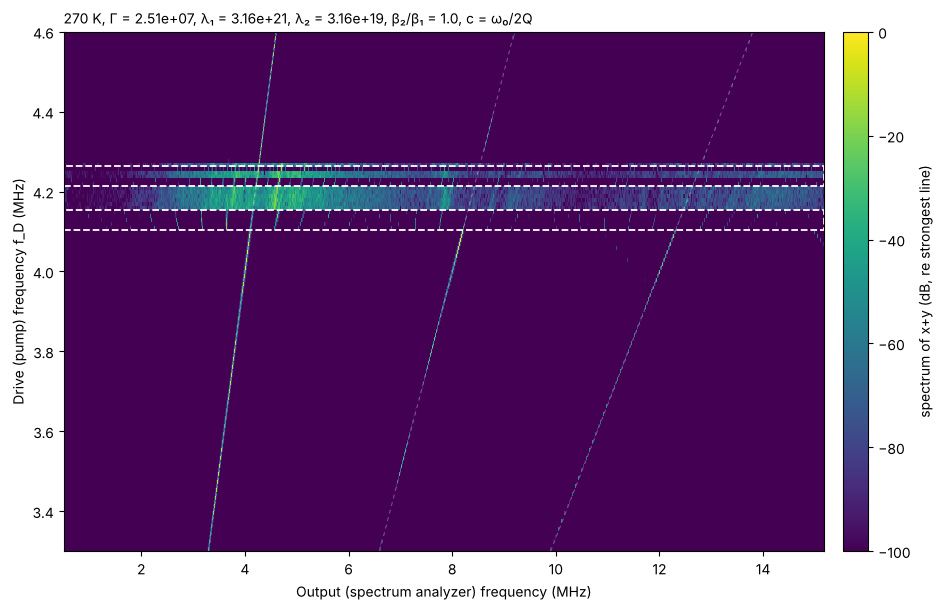

131 drive steps in 18.5 s.  Comb regions (dashed boxes): 4.1100–4.1500 MHz (5/5 steps comb, median Δf ≈ 484 kHz); 4.2200–4.2600 MHz (3/5 steps comb, median Δf ≈ 216 kHz).  Chaotic steps: 9.


In [ ]:
res = drive_map(fD_start=3.3e6, fD_stop=4.6e6, n_steps=131, damping="w0/2Q", Q2=1220, beta2_ratio=1.0)


### Interactive: map with the explorer's current settings
Set the model in the explorer above (temperature, coupling form, damping, Γ, λ₁, λ₂, β₂, Q₂, α, initial conditions), then choose the drive range here and press **Run map**. The explorer's f_D and ramp sliders are not used: the map supplies its own drive sweep.

In [ ]:
S2 = {"description_width": "150px"}; L2 = W.Layout(width="440px")
m_range = W.FloatRangeSlider(value=[3.3, 4.6], min=3.0, max=5.0, step=0.01, description="f_D range (MHz)", readout_format=".2f", style=S2, layout=L2)
m_steps = W.IntSlider(value=131, min=11, max=401, step=10, description="Drive steps", style=S2, layout=L2)
m_sig   = W.Dropdown(options=["x+y", "x", "y"], value="x+y", description="Signal", style=S2, layout=L2)
m_auto  = W.Checkbox(value=True, description="Auto settle (5 ring-down times)", style=S2)
m_set   = W.FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, description="Settle per step (ms)", style=S2, layout=L2)
m_fft   = W.FloatSlider(value=0.5, min=0.1, max=3.0, step=0.1, description="FFT per step (ms)", style=S2, layout=L2)
m_vmin  = W.IntSlider(value=-100, min=-140, max=-40, step=5, description="Color floor (dB)", style=S2, layout=L2)
m_run   = W.Button(description="Run map", button_style="info", icon="th", layout=W.Layout(width="200px", height="38px"))
m_info  = W.HTML(); m_out = W.Output()

def on_map(_=None):
    m_run.disabled = True; m_run.description = "Running..."
    n = m_steps.value; per_ms = (1.5 if m_auto.value else m_set.value) + m_fft.value
    m_info.value = f"<span style='color:#666'>Simulating {n} drive steps (roughly {0.08*n*per_ms:.0f} s)...</span>"
    try:
        with m_out:
            m_out.clear_output(wait=True)
            r = drive_map(fD_start=m_range.value[0]*1e6, fD_stop=m_range.value[1]*1e6, n_steps=n, signal=m_sig.value,
                          t_settle=None if m_auto.value else m_set.value*1e-3, t_fft=m_fft.value*1e-3, vmin=m_vmin.value,
                          T_K=w_T.value, Gamma=w_G.value, lam1=w_l1.value, lam2=w_l2.value, beta2_ratio=w_b2.value,
                          alpha1=w_a1.value, alpha2=w_a2.value, Q2=w_Q2.value, form=w_form.value, damping=w_damp.value,
                          y_seed=w_ys.value*1e-9, x0_from_table=w_x0.value)
        m_info.value = f"Done in {r['seconds']:.1f} s."
    finally:
        m_run.disabled = False; m_run.description = "Run map"

m_run.on_click(on_map)
display(W.VBox([W.HTML("<b>Drive-frequency map</b> (model settings come from the explorer above)"),
                W.HBox([W.VBox([m_range, m_steps, m_sig]), W.VBox([m_auto, m_set, m_fft, m_vmin])]), m_run, m_info, m_out]))
